# Caso Práctico Unidad 3

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from datetime import date
import holidays
import plotly.graph_objs as go
from plotly.offline import iplot
import plotly.offline as pyo
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, MaxAbsScaler, RobustScaler
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

## Preprocesamiento y Preparación de datos

In [26]:
#carga de datos
df = pd.read_csv('PJME_hourly.csv')
df.head()

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [27]:
#visualizacion de datos
def plot_dataset(df, title):
    data = []

    value = go.Scatter(
        x=df.index,
        y=df.value,
        mode="lines",
        name="values",
        marker=dict(),
        text=df.index,
        line=dict(color="rgba(0,0,0, 0.3)"),
    )
    data.append(value)

    layout = dict(
        title=title,
        xaxis=dict(title="Date", ticklen=5, zeroline=False),
        yaxis=dict(title="Value", ticklen=5, zeroline=False),
    )

    fig = dict(data=data, layout=layout)
    iplot(fig)

In [28]:
df = df.set_index(['Datetime'])
df = df.rename(columns={'PJME_MW': 'value'})

df.index = pd.to_datetime(df.index)
if not df.index.is_monotonic_increasing:
    df = df.sort_index()

plot_dataset(df, title='PJME: Consumo de energía estimado en Megawatts (MW)')

Se observa un comportamiento claramente estacional y periódico, con patrones repetitivos a lo largo del tiempo y variaciones frecuentes en la demanda energética. Además, existen picos elevados de consumo en determinados periodos, aunque la serie mantiene una estructura relativamente estable

In [29]:
#transformamos la serie temporal en un problema de regresión supervisada
#creamos el vector de time-delay embedding
def create_time_delay_embedding(data, horizon=6, final_lag=24, column="y", column_index=None):
    df = pd.DataFrame()
    df["y"] = data[column].copy()
    for i in range(horizon, final_lag+1):
        df["lag_{}".format(i)] = data[column].shift(i)
    if column_index is None:
        df.index = data.index
    else:
        df.index = data[column_index]
    return df

In [30]:
#usamos 100 horas de contexto para predecir
final_lag = 100
horizon = 1

df_time_delay = create_time_delay_embedding(df, horizon=horizon, final_lag=final_lag, column="value")
df_time_delay = df_time_delay.dropna()

/tmp/ipykernel_3488/3637485423.py:7: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`



In [31]:
#añadimos features de calendario
df_features = (
                df_time_delay
                .assign(hour = df_time_delay.index.hour)
                .assign(day = df_time_delay.index.day)
                .assign(month = df_time_delay.index.month)
                .assign(day_of_week = df_time_delay.index.dayofweek)
                # .assign(week_of_year = df.index.week)
              )

In [32]:
df_features.head()

,y,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,...,lag_95,lag_96,lag_97,lag_98,lag_99,lag_100,hour,day,month,day_of_week
Datetime,,,,,,,,,,,,,,,,,,,,,
2002-01-05 05:00:00,26822.0,26669.0,27034.0,27501.0,28635.0,30924.0,33202.0,35368.0,36762.0,37539.0,...,28654.0,28057.0,27899.0,28357.0,29265.0,30393.0,5,5,1,5
2002-01-05 06:00:00,27399.0,26822.0,26669.0,27034.0,27501.0,28635.0,30924.0,33202.0,35368.0,36762.0,...,29308.0,28654.0,28057.0,27899.0,28357.0,29265.0,6,5,1,5
2002-01-05 07:00:00,28557.0,27399.0,26822.0,26669.0,27034.0,27501.0,28635.0,30924.0,33202.0,35368.0,...,29595.0,29308.0,28654.0,28057.0,27899.0,28357.0,7,5,1,5
2002-01-05 08:00:00,29709.0,28557.0,27399.0,26822.0,26669.0,27034.0,27501.0,28635.0,30924.0,33202.0,...,29943.0,29595.0,29308.0,28654.0,28057.0,27899.0,8,5,1,5
2002-01-05 09:00:00,31241.0,29709.0,28557.0,27399.0,26822.0,26669.0,27034.0,27501.0,28635.0,30924.0,...,30692.0,29943.0,29595.0,29308.0,28654.0,28057.0,9,5,1,5


In [33]:
#añadimos informacion sobre qué dias son festivos
us_holidays = holidays.US()

def is_holiday(date):
    date = date.replace(hour = 0)
    return 1 if (date in us_holidays) else 0

def add_holiday_col(df, holidays):
    return df.assign(is_holiday = df.index.to_series().apply(is_holiday))


df_features = add_holiday_col(df_features, us_holidays)
df_features.head(3)

,y,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,...,lag_96,lag_97,lag_98,lag_99,lag_100,hour,day,month,day_of_week,is_holiday
Datetime,,,,,,,,,,,,,,,,,,,,,
2002-01-05 05:00:00,26822.0,26669.0,27034.0,27501.0,28635.0,30924.0,33202.0,35368.0,36762.0,37539.0,...,28057.0,27899.0,28357.0,29265.0,30393.0,5,5,1,5,0
2002-01-05 06:00:00,27399.0,26822.0,26669.0,27034.0,27501.0,28635.0,30924.0,33202.0,35368.0,36762.0,...,28654.0,28057.0,27899.0,28357.0,29265.0,6,5,1,5,0
2002-01-05 07:00:00,28557.0,27399.0,26822.0,26669.0,27034.0,27501.0,28635.0,30924.0,33202.0,35368.0,...,29308.0,28654.0,28057.0,27899.0,28357.0,7,5,1,5,0


In [34]:
#dividimos el dataset en test y train

def feature_label_split(df, target_col):
    y = df[[target_col]]
    X = df.drop(columns=[target_col])
    return X, y

def train_val_test_split(df, target_col, test_ratio):
    val_ratio = test_ratio / (1 - test_ratio)
    X, y = feature_label_split(df, target_col)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_ratio, shuffle=False)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=val_ratio, shuffle=False)
    return X_train, X_val, X_test, y_train, y_val, y_test

#aplicamos normalizacion MinMax

def get_scaler(scaler):
    scalers = {
        "minmax": MinMaxScaler,
        "standard": StandardScaler,
        "maxabs": MaxAbsScaler,
        "robust": RobustScaler,
    }
    return scalers.get(scaler.lower())()

X_train, X_val, X_test, y_train, y_val, y_test = train_val_test_split(df_features, 'y', 0.2)

In [35]:
#realizamos el escalado de datos

scaler = get_scaler('minmax')
X_train_arr = scaler.fit_transform(X_train)
X_val_arr = scaler.transform(X_val)
X_test_arr = scaler.transform(X_test)

y_train_arr = scaler.fit_transform(y_train)
y_val_arr = scaler.transform(y_val)
y_test_arr = scaler.transform(y_test)

In [36]:
# Número de muestras procesadas en cada iteración
batch_size = 64

# Convertimos los datos de entrenamiento y validación a tensores de PyTorch

train_features = torch.Tensor(X_train_arr)
train_targets = torch.Tensor(y_train_arr)
val_features = torch.Tensor(X_val_arr)
val_targets = torch.Tensor(y_val_arr)
test_features = torch.Tensor(X_test_arr)
test_targets = torch.Tensor(y_test_arr)

# Creamos datasets de PyTorch para entrenamiento, validación y prueba

train = TensorDataset(train_features, train_targets)
val = TensorDataset(val_features, val_targets)
test = TensorDataset(test_features, test_targets)

#creamos dataloaders para entrenamiento, validación y prueba y para evaluar muestra a muestra

train_loader = DataLoader(train, batch_size=batch_size, shuffle=False, drop_last=True)
val_loader = DataLoader(val, batch_size=batch_size, shuffle=False, drop_last=True)
test_loader = DataLoader(test, batch_size=batch_size, shuffle=False, drop_last=True)
test_loader_one = DataLoader(test, batch_size=1, shuffle=False, drop_last=True)

En esta etapa se realizó el procesamiento y preparación del conjunto de datos para adaptarlo a modelos de predicción de series temporales mediante Deep Learning. Primero se cargó el dataset y se transformó la variable temporal al formato datetime, utilizándola como índice para conservar el orden cronológico de la serie. Posteriormente, se realizó una visualización inicial del consumo energético, observándose patrones periódicos y comportamientos estacionales a lo largo del tiempo.

A continuación, se aplicó una transformación basada en retardos temporales (lags), utilizando las 100 observaciones anteriores como variables de entrada para convertir la serie temporal en un problema supervisado. Además, se incorporaron variables temporales adicionales como la hora, el día, el mes y el día de la semana para facilitar la detección de patrones cíclicos por parte del modelo.

Finalmente, el conjunto de datos se dividió en entrenamiento, validación y prueba manteniendo el orden temporal de las observaciones. Después, se aplicó una normalización mediante MinMaxScaler y los datos fueron convertidos a tensores de PyTorch y organizados mediante DataLoader, permitiendo procesar la información en lotes durante el entrenamiento y evaluación de la red neuronal.

## Definición y Entrenamiento del modelo

In [37]:
import torch.nn as nn

#La clase LSTMModel inicia un módulo LSTM basado en la clase nn.Module de PyTorch.
class LSTMModel(nn.Module):

    #El método __init__ que inicia una instancia de LSTM.
    def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, dropout_prob):

        super(LSTMModel, self).__init__()

        # Definiendo el número de capas y los nodos en cada capa
        self.hidden_dim = hidden_dim
        self.layer_dim = layer_dim

        # Capas LSTM
        self.lstm = nn.LSTM(
            input_dim, hidden_dim, layer_dim, batch_first=True, dropout=dropout_prob
        )

        # Capa completamente conectada
        self.fc = nn.Linear(hidden_dim, output_dim)

    #El método forward toma el tensor de entrada x y realiza la propagación hacia adelante
    def forward(self, x):

        # Inicializando el estado oculto para la primera entrada con ceros
        h0 = torch.zeros(self.layer_dim, x.size(0), self.hidden_dim, device=x.device).requires_grad_()
        # Inicializando el estado de celda para la primera entrada con ceros
        c0 = torch.zeros(self.layer_dim, x.size(0), self.hidden_dim, device=x.device).requires_grad_()

        # Necesitamos desvincular porque estamos haciendo retropropagación truncada a través del tiempo (BPTT)
        # Si no lo hacemos, retrocederemos hasta el principio incluso después de pasar por otro batch
        # Propagación hacia adelante pasando la entrada, el estado oculto y el estado de celda al modelo
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))

        # Reorganizando las salidas en la forma de (tamaño del batch, longitud de secuencia, tamaño oculto)
        # para que pueda encajar en la capa completamente conectada
        out = out[:, -1, :]

        # Convertir el estado final a nuestra forma de salida deseada (tamaño del batch, output_dim)
        out = self.fc(out)

        return out


In [47]:
def get_model(model, model_params):
    models = {
        "lstm": LSTMModel,
         }
    return models.get(model.lower())(**model_params)

In [48]:
#La clase Optimization es una clase auxiliar que permite entrenar, validar y predecir
class Optimization:

    def __init__(self, model, loss_fn, optimizer):

        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = optimizer
        self.train_losses = []
        self.val_losses = []

    #El método train_step completa un paso de entrenamiento.
    def train_step(self, x, y):

        # Establece el modelo en modo de entrenamiento
        self.model.train()

        # Realiza predicciones
        yhat = self.model(x)

         # Calcula la pérdida
        loss = self.loss_fn(y, yhat)

        # Calcula los gradientes
        loss.backward()

        # Actualiza los parámetros y pone a cero los gradientes
        self.optimizer.step()
        self.optimizer.zero_grad()

        # Devuelve la pérdida
        return loss.item()

    #El método train realiza el entrenamiento del modelo
    def train(self, train_loader, val_loader, batch_size=64, n_epochs=50, n_features=1):


        model_path = f'{self.model}_{datetime.now().strftime("%Y-%m-%d %H:%M:%S")}'

        for epoch in range(1, n_epochs + 1):
            batch_losses = []
            for x_batch, y_batch in train_loader:
                x_batch = x_batch.view([batch_size, -1, n_features])
                y_batch = y_batch
                loss = self.train_step(x_batch, y_batch)
                batch_losses.append(loss)
            training_loss = np.mean(batch_losses)
            self.train_losses.append(training_loss)

            with torch.no_grad():
                batch_val_losses = []
                for x_val, y_val in val_loader:
                    x_val = x_val.view([batch_size, -1, n_features])
                    y_val = y_val
                    self.model.eval()
                    yhat = self.model(x_val)
                    val_loss = self.loss_fn(y_val, yhat).item()
                    batch_val_losses.append(val_loss)
                validation_loss = np.mean(batch_val_losses)
                self.val_losses.append(validation_loss)

            if (epoch <= 10) | (epoch % 50 == 0):
                print(
                    f"[{epoch}/{n_epochs}] Training loss: {training_loss:.4f}\t Validation loss: {validation_loss:.4f}"
                )

        torch.save(self.model.state_dict(), model_path)

    #El método evaluate realiza la evaluación del modelo
    def evaluate(self, test_loader, batch_size=1, n_features=1):

        with torch.no_grad():
            predictions = []
            values = []
            for x_test, y_test in test_loader:
                x_test = x_test.view([batch_size, -1, n_features])
                y_test = y_test
                self.model.eval()
                yhat = self.model(x_test)
                yhat=yhat.cpu().data.numpy()
                predictions.append(yhat)
                y_test=y_test.cpu().data.numpy()
                values.append(y_test)

        return predictions, values

    #El método plot_losses traza los valores de pérdida calculados para entrenamiento y validación
    def plot_losses(self):

        plt.style.use('ggplot')
        plt.figure(figsize=(10,5))
        plt.plot(self.train_losses, label="Training loss")
        plt.plot(self.val_losses, label="Validation loss")
        plt.legend()
        plt.title("Losses")
        plt.show()
        plt.close()

Se definieron los hiperparámetros principales de la arquitectura LSTM, incluyendo el número de capas ocultas, tamaño del batch, número de épocas y tasa de aprendizaje

In [49]:
def General_Settings(model_name):

        input_dim = len(X_train.columns)
        output_dim = 1
        hidden_dim = 64
        layer_dim = 3
        batch_size = 64
        dropout = 0.2
        n_epochs = 20
        learning_rate = 1e-3
        weight_decay = 1e-6

        model_params = {'input_dim': input_dim,
                        'hidden_dim' : hidden_dim,
                        'layer_dim' : layer_dim,
                        'output_dim' : output_dim,
                        'dropout_prob' : dropout}
        model = get_model(model_name, model_params)
        loss_fn = nn.MSELoss(reduction="mean")
        optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

        opt = Optimization(model=model, loss_fn=loss_fn, optimizer=optimizer)
        opt.train(train_loader, val_loader, batch_size=batch_size, n_epochs=n_epochs, n_features=input_dim)
        opt.plot_losses()

        predictions, values = opt.evaluate(
            test_loader_one,
            batch_size=1,
            n_features=input_dim
        )
        return predictions,values

Define la configuración general del modelo LSTM, incluyendo hiperparámetros, función de pérdida, optimizador, entrenamiento, representación de pérdidas y evaluación final sobre el conjunto de prueba.

In [50]:
def inverse_transform(scaler, df, columns):
    for col in columns:
        df[col] = scaler.inverse_transform(df[col])
    return df


def format_predictions(predictions, values, df_test, scaler, col_name="y"):
    vals = np.concatenate(values, axis=0).ravel()
    preds = np.concatenate(predictions, axis=0).ravel()
    df_result = pd.DataFrame(data={col_name: vals, "prediction": preds}, index=df_test.head(len(vals)).index)
    df_result = df_result.sort_index()
    df_result = inverse_transform(scaler, df_result, [[col_name, "prediction"]])
    return df_result

Realiza la transformación inversa del escalado y organiza las predicciones del modelo junto con los valores reales para facilitar su comparación y análisis.

In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_metrics(df, col_name="y"):
    result_metrics = {'mae' : mean_absolute_error(df[col_name], df.prediction),
                      'rmse' : mean_squared_error(df[col_name], df.prediction) ** 0.5,
                      'r2' : r2_score(df[col_name], df.prediction)}

    print("Mean Absolute Error:       ", result_metrics["mae"])
    print("Root Mean Squared Error:   ", result_metrics["rmse"])
    print("R^2 Score:                 ", result_metrics["r2"])
    return result_metrics

[1/20] Training loss: 0.0056	 Validation loss: 0.0056
[2/20] Training loss: 0.0029	 Validation loss: 0.0054
[3/20] Training loss: 0.0023	 Validation loss: 0.0046
[4/20] Training loss: 0.0018	 Validation loss: 0.0040
[5/20] Training loss: 0.0013	 Validation loss: 0.0029
[6/20] Training loss: 0.0011	 Validation loss: 0.0017
[7/20] Training loss: 0.0009	 Validation loss: 0.0008
[8/20] Training loss: 0.0008	 Validation loss: 0.0006
[9/20] Training loss: 0.0007	 Validation loss: 0.0007
[10/20] Training loss: 0.0007	 Validation loss: 0.0007


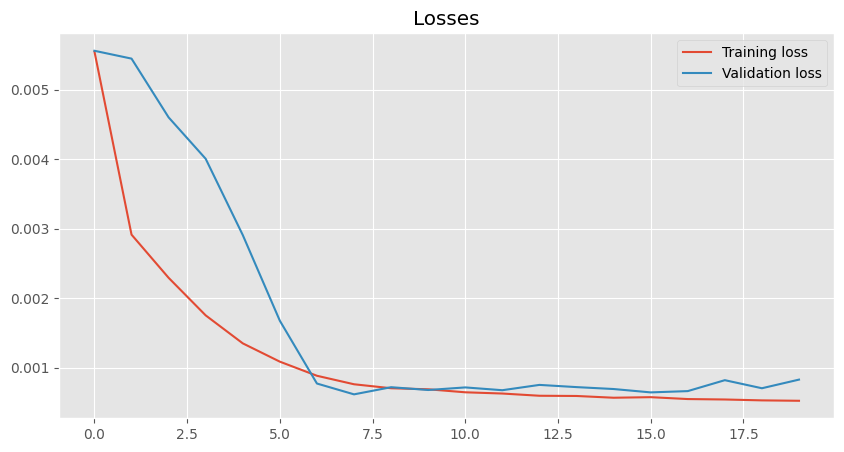

Mean Absolute Error:        1118.8748779296875
Root Mean Squared Error:    1280.2721390391966
R^2 Score:                  0.9610911011695862


In [52]:
predictions, values = General_Settings("lstm")

df_result = format_predictions(
    predictions,
    values,
    X_test,
    scaler,
    col_name="y"
)

metrics = calculate_metrics(df_result)

La curva de aprendizaje obtenida muestra una disminución progresiva tanto de la pérdida de entrenamiento como de validación a medida que avanzan las épocas, lo que indica que el modelo LSTM aprende correctamente los patrones presentes en la serie temporal. Ambas curvas presentan un comportamiento muy similar y convergen hacia valores bajos, sin observarse diferencias significativas entre ellas, lo que sugiere una buena capacidad de generalización y ausencia de sobreajuste. Además, las métricas obtenidas refuerzan este buen rendimiento, alcanzando un MAE de aproximadamente 1118, un RMSE de 1280 y un coeficiente R² de 0.96, indicando que el modelo es capaz de explicar alrededor del 96% de la variabilidad del consumo energético y generar predicciones muy próximas a los valores reales.

In [53]:
#Define un modelo baseline basado en regresión lineal para comparar posteriormente el rendimiento del modelo LSTM.
def build_baseline_model(df, test_ratio, target_col):
    X, y = feature_label_split(df, target_col)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_ratio, shuffle=False
    )
    model = LinearRegression()
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    result = pd.DataFrame(y_test)
    result["prediction"] = prediction
    result = result.sort_index()

    return result

In [57]:
import matplotlib.pyplot as plt

#representación gráfica interactiva que compara los valores reales de la serie temporal, las predicciones del modelo LSTM y la baseline de regresión lineal.
plt.style.use('ggplot')

def plot_predictions(df_result, df_baseline):
    data = []

    value = go.Scatter(
        x=df_result.index,
        y=df_result.y,
        mode="lines",
        name="values",
        marker=dict(),
        text=df_result.index,
        line=dict(color="rgba(0,0,0, 0.3)"),
    )
    data.append(value)

    baseline = go.Scatter(
        x=df_baseline.index,
        y=df_baseline.prediction,
        mode="lines",
        line={"dash": "dot"},
        name='linear regression',
        marker=dict(),
        text=df_baseline.index,
        opacity=0.8,
    )
    data.append(baseline)

    prediction = go.Scatter(
        x=df_result.index,
        y=df_result.prediction,
        mode="lines",
        line={"dash": "dot"},
        name='predictions',
        marker=dict(),
        text=df_result.index,
        opacity=0.8,
    )
    data.append(prediction)

    layout = dict(
        title="Predictions vs Actual Values for the dataset",
        xaxis=dict(title="Time", ticklen=5, zeroline=False),
        yaxis=dict(title="Value", ticklen=5, zeroline=False),
    )

    fig = go.Figure(data=data, layout=layout)
    fig.show()


## Validación

[1/20] Training loss: 0.0054	 Validation loss: 0.0063
[2/20] Training loss: 0.0029	 Validation loss: 0.0055
[3/20] Training loss: 0.0021	 Validation loss: 0.0044
[4/20] Training loss: 0.0016	 Validation loss: 0.0040
[5/20] Training loss: 0.0013	 Validation loss: 0.0031
[6/20] Training loss: 0.0010	 Validation loss: 0.0017
[7/20] Training loss: 0.0009	 Validation loss: 0.0008
[8/20] Training loss: 0.0008	 Validation loss: 0.0006
[9/20] Training loss: 0.0007	 Validation loss: 0.0005
[10/20] Training loss: 0.0006	 Validation loss: 0.0005


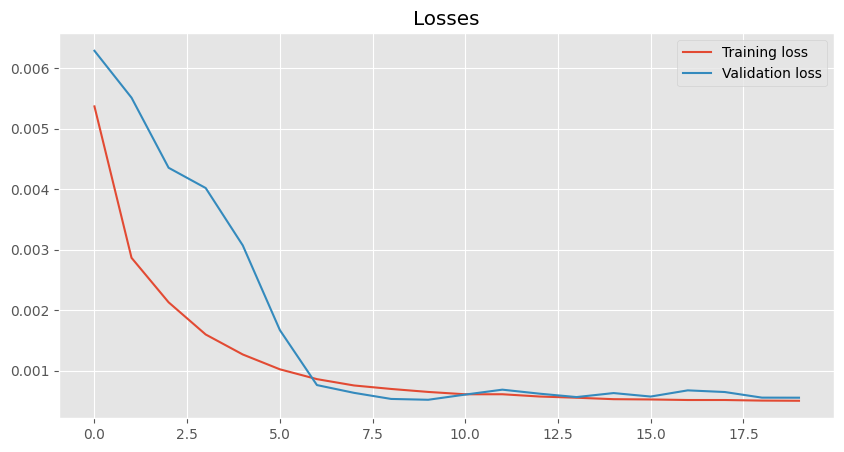

Mean Absolute Error:        870.7431030273438
Root Mean Squared Error:    1046.9397666532684
R^2 Score:                  0.9739812016487122
{'mae': 870.7431030273438, 'rmse': 1046.9397666532684, 'r2': 0.9739812016487122}
Mean Absolute Error:        202.35149307381565
Root Mean Squared Error:    280.7355422353328
R^2 Score:                  0.9981291501224682
{'mae': 202.35149307381565, 'rmse': 280.7355422353328, 'r2': 0.9981291501224682}


In [56]:
#volución de las pérdidas de entrenamiento y validación durante las primeras épocas del modelo LSTM, permitiendo observar el aprendizaje progresivo de la red neuronal
model_name='lstm'
predictions, values=General_Settings(model_name)
df_result=format_predictions(predictions, values, X_test, scaler)
print(calculate_metrics(df_result))
df_baseline = build_baseline_model(df_features, 0.2, 'y')
print(calculate_metrics(df_baseline))
plot_predictions(df_result, df_baseline)

La validación final muestra que tanto el modelo LSTM como la regresión lineal son capaces de aproximar correctamente la evolución del consumo energético, aunque la regresión lineal obtiene métricas ligeramente mejores en este caso concreto. La curva de aprendizaje del modelo LSTM refleja una reducción estable de las pérdidas de entrenamiento y validación, indicando un aprendizaje adecuado y sin signos claros de sobreajuste. Además, la gráfica comparativa entre valores reales y predicciones muestra que ambos modelos siguen de forma bastante precisa el comportamiento general de la serie temporal, reproduciendo correctamente la mayoría de los picos y variaciones del consumo eléctrico.